In [1]:
import sys
import os

class NotebookLogger:
    def __init__(self, filename, stream):
        self.stream = stream
        self.filename = filename

    def write(self, data):
        self.stream.write(data)  # Keeps displaying in the notebook
        with open(self.filename, 'a') as f:
            f.write(data)        # Appends to the log file

    def flush(self):
        self.stream.flush()

    def __getattr__(self, attr):
        return getattr(self.stream, attr)

# This will capture everything printed to the notebook into "all_outputs.log"
sys.stdout = NotebookLogger('all_outputs.log', sys.stdout)
sys.stderr = NotebookLogger('all_outputs.log', sys.stderr)

class RedirectOSOutput:
    """Context manager to redirect OS-level file descriptors 1 and 2 to a file."""
    def __init__(self, filename):
        self.filename = filename
        self.log_file = None
        self.original_stdout_fd = None
        self.original_stderr_fd = None

    def __enter__(self):
        self.log_file = open(self.filename, 'a')
        self.original_stdout_fd = os.dup(1)
        self.original_stderr_fd = os.dup(2)
        os.dup2(self.log_file.fileno(), 1)
        os.dup2(self.log_file.fileno(), 2)
        return self

    def __exit__(self, exc_type, exc_val, exc_tb):
        os.dup2(self.original_stdout_fd, 1)
        os.dup2(self.original_stderr_fd, 2)
        os.close(self.original_stdout_fd)
        os.close(self.original_stderr_fd)
        self.log_file.close()

In [2]:
import matplotlib.pyplot as plt

import numpy as np
import scipy as sp

np.seterr(all="ignore")

from threeML import *
set_threeML_style()
silence_warnings()

from threeML.io.package_data import get_path_of_data_file
from threeML.io import update_logging_level
from threeML.utils.data_download.Fermi_LAT.download_LAT_data import LAT_dataset
from astropy.io import fits as pyfits

SMALL_SIZE = 15
MEDIUM_SIZE = 15
BIGGER_SIZE = 20

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

# Now import 3ML
import threeML


# This if you want to toggle different type of logging level.
update_logging_level("INFO")
log.error("error")
log.info("info")
log.debug("debug")

/home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/astromodels/utils/file_utils.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


13:00:02 WARNING   The naima package is not available. Models that depend on it will not be         ]8;id=596842;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=158509;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/astromodels/functions/functions_1D/functions.py#47\47]8;;\
                  available                                                                                        

         WARNING   The GSL library or the pygsl wrapper cannot be loaded. Models that depend on it  ]8;id=959927;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=812950;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/astromodels/functions/functions_1D/functions.py#68\68]8;;\
                  will not be available.                                                                           

         WARNING   The ebltable package is not available. Models that depend on it will not be     ]8;id=920408;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/astromodels/functions/functions_1D/absorption.py\absorption.py]8;;\:]8;id=662417;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/astromodels/functions/functions_1D/absorption.py#33\33]8;;\
                  available                                                                                        

         INFO      Starting 3ML!                                                                     ]8;id=89159;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=690441;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/__init__.py#39\39]8;;\

...

         WARNING   Env. variable OMP_NUM_THREADS is not set. Please set it to 1 for optimal         ]8;id=605534;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=921451;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/__init__.py#387\387]8;;\
                  performances in 3ML                                                                              

         WARNING   Env. variable MKL_NUM_THREADS is not set. Please set it to 1 for optimal         ]8;id=294576;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=787760;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/__init__.py#387\387]8;;\
                  performances in 3ML                                                                              

         WARNING   Env. variable NUMEXPR_NUM_THREADS is not set. Please set it to 1 for optimal     ]8;id=33567;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=563004;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/__init__.py#387\387]8;;\
                  performances in 3ML                                                                              

         ERROR     error                                                                           ]8;id=805663;file:///tmp/ipykernel_41870/4214338045.py\4214338045.py]8;;\:]8;id=723794;file:///tmp/ipykernel_41870/4214338045.py#40\40]8;;\

         INFO      info                                                                            ]8;id=668390;file:///tmp/ipykernel_41870/4214338045.py\4214338045.py]8;;\:]8;id=388367;file:///tmp/ipykernel_41870/4214338045.py#41\41]8;;\

Gtburst contains all the classes and methods to perform Fermi LAT data. It internally uses the official fermitools software. Here an example to list the IRFS available:

In [3]:
from GtBurst import IRFS

irfs = IRFS.IRFS.keys()
print(irfs)

odict_keys(['p7rep_transient', 'p7rep_source', 'p7rep_clean', 'p7rep_ultraclean', 'p8r2_transient100e', 'p8r2_transient100', 'p8r2_transient020e', 'p8r2_transient020', 'p8r2_transient010e', 'p8r2_transient010', 'p8r2_source', 'p8r2_clean', 'p8r2_ultraclean', 'p8r2_ultracleanveto', 'p8r2_transient100s', 'p8r2_transient015s', 'p8_transient100e', 'p8_transient100', 'p8_transient020e', 'p8_transient020', 'p8_transient010e', 'p8_transient010', 'p8_source', 'p8_clean', 'p8_ultraclean', 'p8_ultracleanveto', 'p8_sourceveto', 'p8_transient100s', 'p8_transient015s'])


The LAT Transient Builder

Let’s see how to make a plug in for the unbinned analysis of Fermi LAT data. First we use the information form a triggered GRB to obtain MET, RA and DEC, that are needed for the analysis.

In [4]:
from GtBurst.TriggerSelector import TriggerSelector

GRBName = "bn200412381"

def findGRB(grb_name):
    a = TriggerSelector()
    a.downloadList()
    myGRB = {}
    for x in a.data:
        if x[0] == GRBName:
            myGRB["MET"] = float(x[1])
            myGRB["RA"] = float(x[3])
            myGRB["DEC"] = float(x[4])
            myGRB["ERR"] = float(x[5])
            return myGRB
            pass
    return None

In [5]:
myGRB = findGRB(GRBName)
print(myGRB)

{'MET': 608375325.707, 'RA': 277.48, 'DEC': 61.79, 'ERR': 0.5}


Then, we download LAT data and we build the transient builder, we want to analyze 1000 seconds since the trigger. Let’s start download the data:

In [6]:
tstart = 0
tstop = 10000

In [7]:
myLATdataset = LAT_dataset()

with RedirectOSOutput('all_outputs.log'):
    myLATdataset.make_LAT_dataset(
        ra=myGRB["RA"],
        dec=myGRB["DEC"],
        radius=12,
        trigger_time=myGRB["MET"],
        tstart=tstart,
        tstop=tstop,
        data_type="Extended",
        destination_directory=".",
        Emin=100.0,
        Emax=10000.0,
    )  # Energies are MeV (this is from 100 MeV to 10 GeV)

13:00:16 INFO      Query parameters:                                                       ]8;id=293030;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py\download_LAT_data.py]8;;\:]8;id=48730;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py#262\262]8;;\

         INFO                          coordfield = 277.4800,61.7900                       ]8;id=803207;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py\download_LAT_data.py]8;;\:]8;id=357286;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py#266\266]8;;\

         INFO                         coordsystem = J2000                                  ]8;id=296675;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py\download_LAT_data.py]8;;\:]8;id=438392;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py#266\266]8;;\

         INFO                          shapefield = 12                                     ]8;id=485143;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py\download_LAT_data.py]8;;\:]8;id=160129;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py#266\266]8;;\

         INFO                           timefield = 608375325.707,608385325.707            ]8;id=192638;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py\download_LAT_data.py]8;;\:]8;id=334164;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py#266\266]8;;\

...

         INFO      Query ID: cad224e4107c901194aa1c6365c857de                              ]8;id=395773;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py\download_LAT_data.py]8;;\:]8;id=962329;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py#271\271]8;;\

13:00:19 INFO      Estimated complete time for your query: 18 seconds                      ]8;id=664516;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py\download_LAT_data.py]8;;\:]8;id=660530;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py#428\428]8;;\

         INFO      If this download fails, you can find your data at                       ]8;id=395044;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py\download_LAT_data.py]8;;\:]8;id=804637;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py#437\437]8;;\
                  https://fermi.gsfc.nasa.gov/cgi-bin/ssc/LAT/QueryResults.cgi?id=L2606110                         
                  33019F357373F33 (when ready)                                                                     

13:00:27 INFO      Downloading FT1 and FT2 files...                                        ]8;id=512199;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py\download_LAT_data.py]8;;\:]8;id=216969;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py#527\527]8;;\

Writing ./bn200412381/gll_cspec_tr_bn200412381_v00.rsp...
time -p gtselect infile=./bn200412381/gll_ft1_tr_bn200412381_v00.fit outfile=__temp_ft1.fits ra=277.48 dec=61.79 rad=15.0 tmin=608375324.707 tmax=608385326.707 emin=10.0 emax=1000000.0 zmin=0.0 zmax=110.0 evclass="INDEF" evtype="INDEF" convtype=-1 phasemin=0.0 phasemax=1.0 evtable="EVENTS" chatter=2 clobber=yes debug=no gui=no mode="ql"
Done.
real 0.03
user 0.02
sys 0.00
Writing ./bn200412381/gll_cspec_tr_bn200412381_v00.pha...
 *  Get energy binning from the response matrix...

    done.

 *  Run gtbindef and gtbin and bin in energy and time...

time -p gtbindef bintype="E" binfile=__ebins.txt outfile=__energyBins.fits energyunits="keV" chatter=2 clobber=yes debug=no gui=no mode="ql"
This is gtbindef version HEAD
real 0.01
user 0.00
sys 0.00
time -p gtbin evfile=/home/void/GRB_DATA/LAT_Test/__temp_ft1.fits scfile=/home/void/GRB_DATA/LAT_Test/bn200412381/gll_ft2_tr_bn200412381_v00.fit outfile=__gtllebin__pha2.pha algorithm="PHA2

We want perform a time resolved analysis. So, first we look at the data. We can play with the ROI selection and the cut.

In [8]:
roi = 10
zmax = 100.0
thetamax = 180.0
irfs = "p8_source"
strategy = "time"
myLATdataset.extract_events(roi, zmax, irfs, thetamax, strategy=strategy)

time -p gtmktime scfile=/home/void/GRB_DATA/LAT_Test/bn200412381/gll_ft2_tr_bn200412381_v00.fit sctable="SC_DATA" filter="(DATA_QUAL>0 || DATA_QUAL==-1) && LAT_CONFIG==1 && IN_SAA!=T && LIVETIME>0 && (ANGSEP(RA_ZENITH,DEC_ZENITH,277.48,61.79)<=(100.0-10))" roicut=no evfile=/home/void/GRB_DATA/LAT_Test/bn200412381/gll_ft1_tr_bn200412381_v00.fit evtable="EVENTS" outfile="gll_ft1_tr_bn200412381_v00_mkt.fit" apply_filter=yes overwrite=no header_obstimes=yes tstart=608375325.707 tstop=608385325.707 gtifile="default" chatter=2 clobber=yes debug=no gui=no mode="ql"
real 0.02
user 0.02
sys 0.00

Using 305 data

time -p gtselect infile=gll_ft1_tr_bn200412381_v00_mkt.fit outfile=gll_ft1_tr_bn200412381_v00_filt.fit ra=277.48 dec=61.79 rad=10.0 tmin=608375325.707 tmax=608385325.707 emin=100.0 emax=10000.0 zmin=0.0 zmax=100.0 evclass=128 evtype=3 convtype=-1 phasemin=0.0 phasemax=1.0 evtable="EVENTS" chatter=2 clobber=yes debug=no gui=no mode="ql"
Done.
real 0.03
user 0.02
sys 0.00

Selected 37 eve

13:00:47 INFO      Extracted 37 events                                                     ]8;id=794802;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py\download_LAT_data.py]8;;\:]8;id=88967;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_download/Fermi_LAT/download_LAT_data.py#670\670]8;;\

In [9]:
%matplotlib inline
with pyfits.open(myLATdataset.filt_file) as event_file:
    lat_events = event_file["EVENTS"].data
event_times = lat_events["TIME"] - myGRB["MET"]

### Time Intervals Configuration
Configure how you want to bin the data for the prompt and extended phases.

In [10]:
from astropy.stats import bayesian_blocks

# --- CONFIGURATION ---
prompt_method = "custom"  # Options: "bayesian" or "custom"
custom_prompt_intervals = [0, 12, 1000, 10000]

extended_method = "none"  # Options: "log", "integrated", or "none"
ext_start = 180.0
ext_stop = 1000.0
num_log_bins = 3

intervals = []

if prompt_method == "bayesian":
    print(f"Calculating Bayesian Blocks from {myLATdataset.filt_file}...")
    try:
        absolute_times = lat_events['TIME']
        zenith_angles = lat_events['ZENITH_ANGLE']
        relative_times = absolute_times - myGRB["MET"]
        
        prompt_mask = (relative_times > -100) & (relative_times < 500) & (zenith_angles <= 100)
        prompt_times = relative_times[prompt_mask]
        
        if len(prompt_times) > 0:
            edges = bayesian_blocks(prompt_times, fitness='events', p0=0.05)
            # Filter edges to only include relevant prompt/early tail bins (e.g., -10s to 200s)
            valid_edges = [float(e) for e in edges if -10 <= e <= 200]
            intervals.extend(valid_edges)
        else:
            print("⚠️ No photons found for Bayesian blocks. Falling back to custom.")
            intervals.extend(custom_prompt_intervals)
    except Exception as e:
        print(f"⚠️ Error with Bayesian blocks: {e}. Falling back to custom.")
        intervals.extend(custom_prompt_intervals)
else:
    intervals.extend(custom_prompt_intervals)

if extended_method == "log":
    start_ext = intervals[-1] if intervals else ext_start
    log_edges = np.logspace(np.log10(start_ext), np.log10(ext_stop), num=num_log_bins + 1)
    if intervals and np.isclose(intervals[-1], log_edges[0]):
        log_edges = log_edges[1:]
    intervals.extend([float(e) for e in log_edges])
elif extended_method == "integrated":
    start_ext = intervals[-1] if intervals else ext_start
    if not intervals or not np.isclose(intervals[-1], start_ext):
        intervals.append(float(start_ext))
    intervals.append(float(ext_stop))

print(f"Final Time Intervals: {intervals}")

# Find max energy photon
max_idx = np.argmax(lat_events["ENERGY"])
max_energy = lat_events["ENERGY"][max_idx]
max_time = event_times[max_idx]
print(f"Max Energy Photon: {max_energy:.2f} MeV at {max_time:.2f} s")

# Display a table of the events
import pandas as pd
df_events = pd.DataFrame({
    "Time [s]": np.array(event_times, dtype=float),
    "Energy [MeV]": np.array(lat_events["ENERGY"], dtype=float)
}).sort_values(by="Time [s]").reset_index(drop=True)

# Save to CSV
df_events.to_csv("energy_vs_time.csv", index=False)
print("Saved energy_vs_time.csv")

# Create tables for the upper plot (Events vs Time)
counts_intervals, _ = np.histogram(event_times, bins=intervals)
df_intervals = pd.DataFrame({
    "Time Start [s]": intervals[:-1],
    "Time End [s]": intervals[1:],
    "Events": counts_intervals
})
df_intervals.to_csv("events_vs_time_intervals.csv", index=False)
print("Saved events_vs_time_intervals.csv")

log_bins = np.logspace(0, 4, 30)
counts_log, _ = np.histogram(event_times, bins=log_bins)
df_log_bins = pd.DataFrame({
    "Time Start [s]": log_bins[:-1],
    "Time End [s]": log_bins[1:],
    "Events": counts_log
})
df_log_bins.to_csv("events_vs_time_log_bins.csv", index=False)
print("Saved events_vs_time_log_bins.csv")

Final Time Intervals: [0, 12, 1000, 10000]
Max Energy Photon: 2427.28 MeV at 4101.34 s
Saved energy_vs_time.csv
Saved events_vs_time_intervals.csv
Saved events_vs_time_log_bins.csv


tstarts and tstops are defined as strings, with somma separated values for the starts and the ends of the time bins: For example tsrats=”0,1,10” and tstops=”1,10,20”. To convert arrays in string we use these few lines of code:

In [11]:
tstarts_prompt = tstops_prompt = ""
tstarts_ext = tstops_ext = ""

for t0, t1 in zip(intervals[:-1], intervals[1:]):
    if t1 < 100:
        tstarts_prompt += "%.4f," % t0
        tstops_prompt += "%.4f," % t1
    else:
        tstarts_ext += "%.4f," % t0
        tstops_ext += "%.4f," % t1

if tstarts_prompt:
    tstarts_prompt = tstarts_prompt[:-1].replace("-", "\\-")
    tstops_prompt = tstops_prompt[:-1].replace("-", "\\-")
    print(f"Prompt tstarts: {tstarts_prompt}")
    print(f"Prompt tstops: {tstops_prompt}")

if tstarts_ext:
    tstarts_ext = tstarts_ext[:-1].replace("-", "\\-")
    tstops_ext = tstops_ext[:-1].replace("-", "\\-")
    print(f"Extended tstarts: {tstarts_ext}")
    print(f"Extended tstops: {tstops_ext}")

Prompt tstarts: 0.0000
Prompt tstops: 12.0000
Extended tstarts: 12.0000,1000.0000
Extended tstops: 1000.0000,10000.0000


First, perform high-energy localization to get precise coordinates.

We can now make an instance the LAT transient builder for time-resolved analysis

In [12]:

LAT_observations = []

if tstarts_prompt:
    print("Running Prompt Intervals (< 100 s)...")
    prompt_builder = TransientLATDataBuilder(
        myLATdataset.grb_name,
        
        # --- Basic Settings ---
        outfile="my_custom_grb_output_prompt",
        datarepository=".",
        
        # --- Time and Space ---
        tstarts=tstarts_prompt,
        tstops=tstops_prompt,
        roi=10.0,
        zmax=100.0,
        thetamax=180.0,
        
        # --- Energy Range (in MeV) ---
        emin=100.0,
        emax=100000.0,
        
        # --- Instrument and Models ---
        irf="p8_source",
        galactic_model="template",
        particle_model="isotr template",
        
        # --- Analysis Options ---
        source_model="PowerLaw2",
        liketype="unbinned",
        optimizeposition="no",
        strategy="time",
        tsmin=15,
        spectralfiles="no",
        
        # --- Advanced / Background Options ---
        fgl_mode="fast",
        remove_fits_files=False,
        filter_GTI=False,
        likelihood_profile=False
    )
    df_prompt = prompt_builder.display(get=True)
    print("Prompt Builder Configuration:")
    print(df_prompt)

if tstarts_ext:
    print("Running Extended Intervals (>= 100 s)...")
    ext_builder = TransientLATDataBuilder(
        myLATdataset.grb_name,
        
        # --- Basic Settings ---
        outfile="my_custom_grb_output_ext",
        datarepository=".",
        
        # --- Time and Space ---
        tstarts=tstarts_ext,
        tstops=tstops_ext,
        roi=10.0,
        zmax=100.0,
        thetamax=180.0,
        
        # --- Energy Range (in MeV) ---
        emin=100.0,
        emax=100000.0,
        
        # --- Instrument and Models ---
        irf="p8_source",
        galactic_model="template",
        particle_model="isotr template",
        
        # --- Analysis Options ---
        source_model="PowerLaw2",
        liketype="unbinned",
        optimizeposition="no",
        strategy="time",
        tsmin=15,
        spectralfiles="no",
        
        # --- Advanced / Background Options ---
        fgl_mode="fast",
        remove_fits_files=False,
        filter_GTI=False,
        likelihood_profile=False
    )
    df_ext = ext_builder.display(get=True)
    print("Extended Builder Configuration:")
    print(df_ext)

Running Prompt Intervals (< 100 s)...
outfile               my_custom_grb_output_prompt
roi                                          10.0
tstarts                                    0.0000
tstops                                    12.0000
zmax                                        100.0
emin                                        100.0
emax                                     100000.0
irf                                     p8_source
galactic_model                           template
particle_model                     isotr template
source_model                            PowerLaw2
tsmin                                          15
strategy                                     time
thetamax                                    180.0
spectralfiles                                  no
liketype                                 unbinned
optimizeposition                               no
datarepository                                  .
ltcube                                           
expomap     

The run method will run (using gtburst) all the fermitools needed to obtain the needed file for the likelihood analysis (livetimecubes, exposure maps. It will also perfom a simple likelihood analysis with the standard likelihood of the fermitools (pylikelihood). The dataproducts created here will be used by threeML to make the fit.

In [13]:
with RedirectOSOutput('all_outputs.log'):
    if tstarts_prompt:
        obs_prompt = prompt_builder.run(include_previous_intervals=True)
        if not isinstance(obs_prompt, list) and not isinstance(obs_prompt, tuple):
            obs_prompt = [obs_prompt]
        LAT_observations.extend(obs_prompt)
        
    if tstarts_ext:
        obs_ext = ext_builder.run(include_previous_intervals=True)
        if not isinstance(obs_ext, list) and not isinstance(obs_ext, tuple):
            obs_ext = [obs_ext]
        LAT_observations.extend(obs_ext)

         INFO      Changing permission to                                              ]8;id=473389;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=813562;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#635\635]8;;\
                  /home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/fermito                             
                  ols/GtBurst/scripts/doTimeResolvedLike.py                                                        

         INFO      Changing permission to                                              ]8;id=899159;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=721883;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#635\635]8;;\
                  /home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/fermito                             
                  ols/GtBurst/gtapps_mp/gtdiffrsp_mp.py                                                            

         INFO      Changing permission to                                              ]8;id=44173;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=438728;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#635\635]8;;\
                  /home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/fermito                             
                  ols/GtBurst/gtapps_mp/gtexpmap_mp.py                                                             

         INFO      Changing permission to                                              ]8;id=140590;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=530333;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#635\635]8;;\
                  /home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/fermito                             
                  ols/GtBurst/gtapps_mp/gtltcube_mp.py                                                             

         INFO      Changing permission to                                              ]8;id=858802;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=951394;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#635\635]8;;\
                  /home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/fermito                             
                  ols/GtBurst/gtapps_mp/gttsmap_mp.py                                                              

...

         INFO      we will grab the data file for you.                                 ]8;id=444723;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=675609;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#727\727]8;;\

         INFO      copied ./bn200412381/gll_ft2_tr_bn200412381_v00.fit to              ]8;id=478765;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=841933;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#743\743]8;;\
                  interval1000.0-10000.0/gll_ft2_tr_bn200412381_v00.fit                                            

         INFO      The ft2 file does not exist. Please examine!                        ]8;id=823792;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=611578;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#726\726]8;;\

         INFO      we will grab the data file for you.                                 ]8;id=80940;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=169350;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#727\727]8;;\

         INFO      copied ./bn200412381/gll_ft2_tr_bn200412381_v00.fit to              ]8;id=64314;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=518237;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#743\743]8;;\
                  interval12.0-1000.0/gll_ft2_tr_bn200412381_v00.fit                                               

At this point we can create the FermiLATLike plugins from each of the observation:

In [14]:
LAT_plugins = {}
for l in LAT_observations:
    LAT_name = "LAT_%06.3f-%06.3f" % (float(l.tstart), float(l.tstop))
    LAT_plugins[LAT_name] = l.to_LATLike()
    pass

FermiLATLike - GTI SUM =  12.0
FermiLATLike - GTI SUM =  12.0
FermiLATLike - GTI SUM =  4148.996945023537
FermiLATLike - GTI SUM =  129.89300000667572


For reference, these are the keys save in the dictionary.

In [15]:
LAT_plugins.keys()

dict_keys(['LAT_00.000-12.000', 'LAT_1000.000-10000.000', 'LAT_12.000-1000.000'])

Now we can perform the fit in each bin. Note that we set the model, and we set some initial values. All the resulting joint likelihood objects are stored in a dictioonary to be used later for plotting.

In [16]:
results = {}
# update_logging_level("DEBUG")

for T0, T1 in zip(intervals[:-1], intervals[1:]):
    GRB = PointSource(
        "GRB", ra=myGRB["RA"], dec=myGRB["DEC"], spectral_shape=Powerlaw_flux()
    )
    model = Model(GRB)
    model.GRB.spectrum.main.Powerlaw_flux.a = 100.0 * u.MeV
    model.GRB.spectrum.main.Powerlaw_flux.b = 10000.0 * u.MeV
    model.GRB.spectrum.main.Powerlaw_flux.F = 1.0
    LAT_name = "LAT_%06.3f-%06.3f" % (T0, T1)
    LAT_model_name = ("LAT%dX%d" % (T0, T1)).replace("-", "n")
    datalist = DataList(LAT_plugins[LAT_name])
    model["GRB.spectrum.main.Powerlaw_flux.F"].bounds = (1e-6, 1e6)
    model["GRB.spectrum.main.Powerlaw_flux.F"].value = 1e-2
    model["GRB.spectrum.main.Powerlaw_flux.index"].value = -2.2
    model["GRB.spectrum.main.Powerlaw_flux.index"].bounds = (-3, 0)
    jl = JointLikelihood(model, datalist, verbose=False)
    model[LAT_model_name + "_GalacticTemplate_Value"].value = 1.0
    model[LAT_model_name + "_GalacticTemplate_Value"].fix = True
    model[LAT_model_name + "_GalacticTemplate_Value"].fix = True
    # model.display( complete=True )
    jl.set_minimizer("minuit")
    jl.fit(compute_covariance=True)
    results[LAT_name] = jl
    pass


Found Isotropic template for irf P8R3_SOURCE_V3: /home/void/miniforge3/envs/fermi/share/fermitools/refdata/fermi/galdiffuse/iso_P8R3_SOURCE_V3_v1.txt

Found Galactic template for IRF. P8R3_SOURCE_V3: /home/void/miniforge3/envs/fermi/share/fermitools/refdata/fermi/galdiffuse/gll_iem_v07.fits

Cutting the template around the ROI: 



13:01:24 INFO      set the minimizer to minuit                                             ]8;id=58295;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=633733;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/classicMLE/joint_likelihood.py#1046\1046]8;;\

         INFO      set the minimizer to MINUIT                                             ]8;id=510864;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=515062;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/classicMLE/joint_likelihood.py#1063\1063]8;;\

Best fit values:

,result,unit
parameter,,
GRB.spectrum.main.Powerlaw_flux.F,(1.8 -0.8 +1.4) x 10^-4,1 / (s cm2)
GRB.spectrum.main.Powerlaw_flux.index,-3.0000 +/- 0.0018,
LAT0X12_IsotropicTemplate_Normalization,(1.0 +/- 0.9) x 10^-1,


...

1.00,-0.00,-0.00
-0.00,1.00,-0.00
-0.00,-0.00,1.00


Values of -log(likelihood) at the minimum:

,-log(likelihood)
LAT1000X10000,343.507349
total,343.507349


Values of statistical measures:

,statistical measures
AIC,694.014699
BIC,697.011312


You can use this function to graphically display the results of your fit (folded model, data and residuals)

Best fit values:

,result,unit
parameter,,
GRB.spectrum.main.Powerlaw_flux.F,(1.8 -0.8 +1.4) x 10^-4,1 / (s cm2)
GRB.spectrum.main.Powerlaw_flux.index,-3.0000 +/- 0.0018,
LAT0X12_IsotropicTemplate_Normalization,(1.0 +/- 0.9) x 10^-1,


Correlation matrix:

1.00,-0.00,-0.00
-0.00,1.00,0.00
-0.00,0.00,1.00


Values of -log(likelihood) at the minimum:

,-log(likelihood)
LAT0X12,15.2911
total,15.2911


Values of statistical measures:

,statistical measures
AIC,12.582201
BIC,33.878038


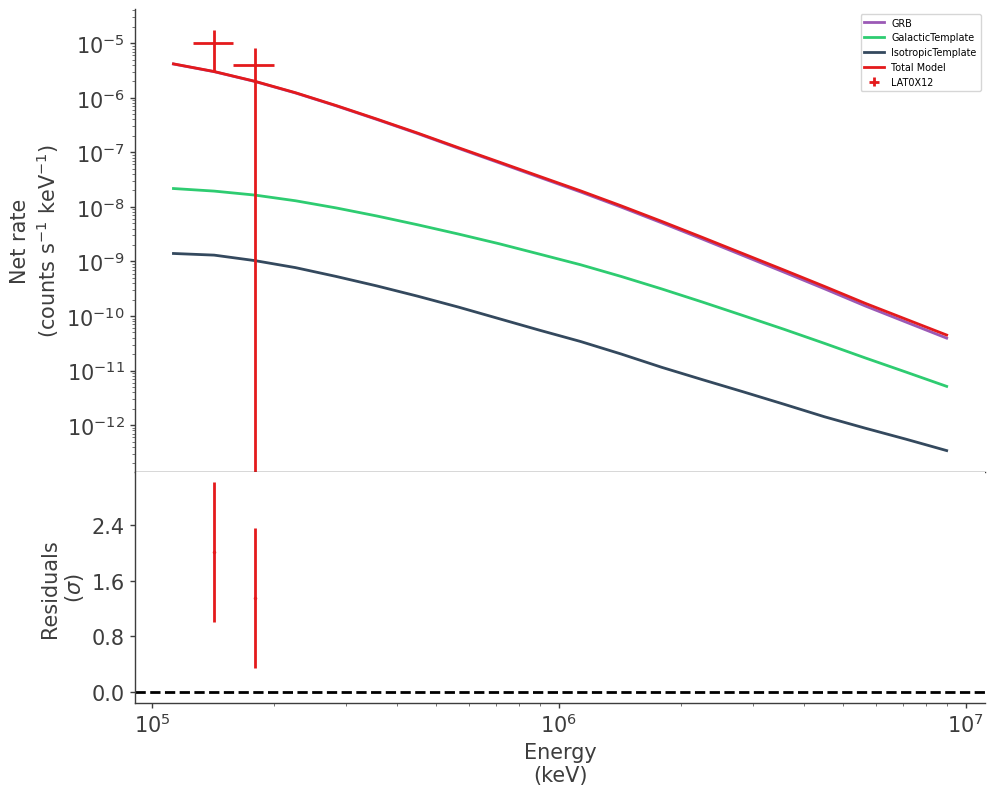

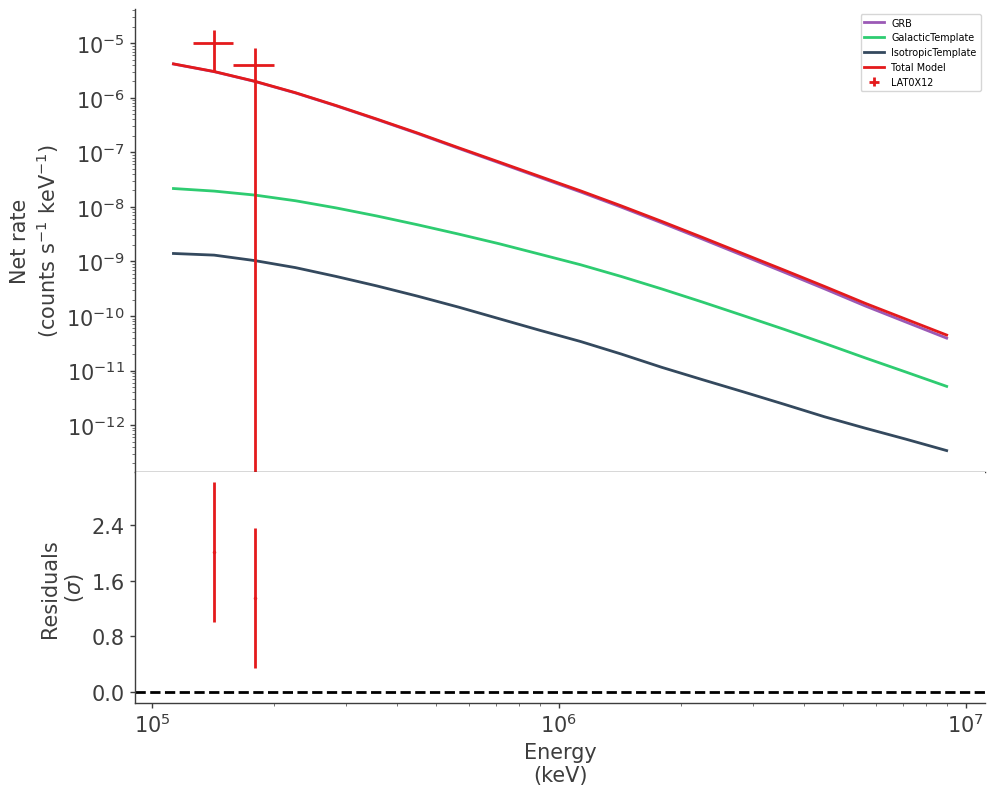

In [17]:
i = 0
T0, T1 = intervals[i], intervals[i + 1]
LAT_name = "LAT_%06.3f-%06.3f" % (T0, T1)
jl = results[LAT_name]
jl.results.display()
display_spectrum_model_counts(jl, figsize=(10, 8))

We can see the evolution of the spectrum with time (not all the bins are diplayed):

processing MLE analyses:   0%|          | 0/3 [00:00<?, ?it/s]

Propagating errors:   0%|          | 0/100 [00:00<?, ?it/s]

Propagating errors:   0%|          | 0/100 [00:00<?, ?it/s]

Propagating errors:   0%|          | 0/100 [00:00<?, ?it/s]

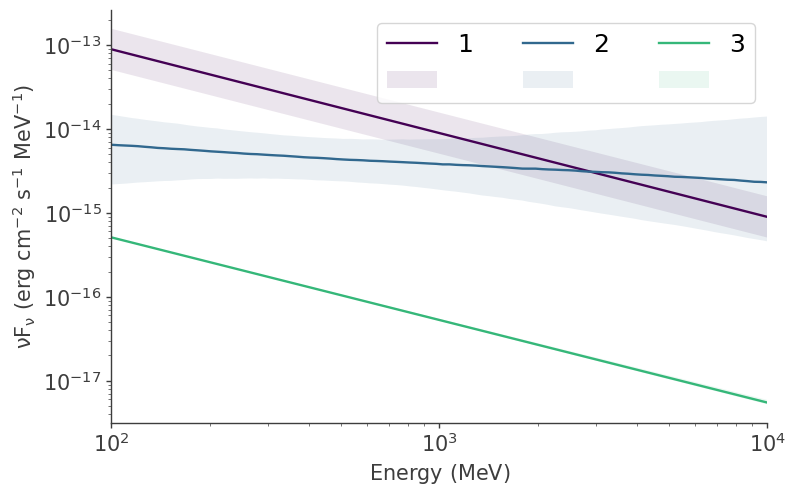

In [18]:
import matplotlib.pyplot as plt  # Ensure imported

fig = plot_spectra(
    *[a.results for a in results.values()],
    ene_min=100 * u.MeV,
    ene_max=10 * u.GeV,
    flux_unit="erg2/(cm2 s MeV)",
    energy_unit="MeV",
    fit_cmap="viridis",
    contour_cmap="viridis",
    contour_style_kwargs=dict(alpha=0.1)
)
fig.set_size_inches(8, 5)
ax = fig.gca()
ax.set_xlabel(r'$\rm Energy~(MeV)$')
ax.set_ylabel(r'$\rm \nu F_\nu~(erg~cm^{-2}~s^{-1}~MeV^{-1})$')

legend = ax.get_legend()  
if legend:
    legend_texts = legend.get_texts()
    try:
        legend_texts[0].set_text('1')
        legend_texts[1].set_text('2')
        legend_texts[2].set_text('3')
    except IndexError:
        pass

ax.legend(['1', '', '2', '', '3', ''], ncol=3, fontsize=18, loc='upper right')

plt.tight_layout()
plt.savefig('lat_ph_idx.pdf',bbox_inches='tight')

Now we can display flux lightcurves and index evolution with time.

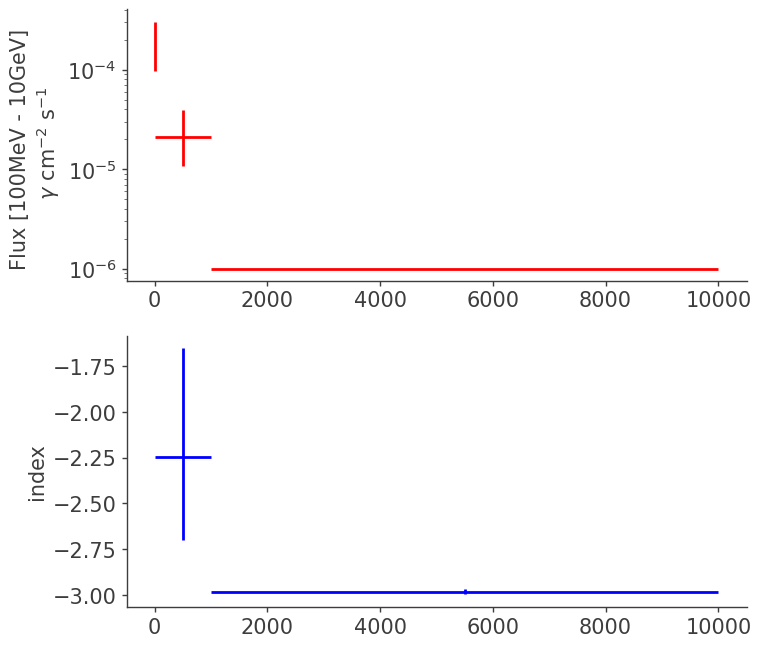

In [19]:
variates = ["F", "index"]
y = {}
for n in variates:
    y[n] = []
    y[n + "_p"] = []
    y[n + "_n"] = []
x = []
dx = []

for T0, T1 in zip(intervals[:-1], intervals[1:]):
    LAT_name = "LAT_%06.3f-%06.3f" % (T0, T1)
    x.append((T1 + T0) / 2)
    dx.append((T1 - T0) / 2)
    jl = results[LAT_name]
    res = jl.results
    mod = res.optimized_model
    ps = mod.point_sources

    for n in variates:
        my_variate = res.get_variates("GRB.spectrum.main.Powerlaw_flux.%s" % n)
        y[n].append(my_variate.median)
        y[n + "_p"].append(my_variate.equal_tail_interval()[1] - my_variate.median)
        y[n + "_n"].append(my_variate.median - my_variate.equal_tail_interval()[0])

fig = plt.figure(figsize=(8, 12))
colors = ["r", "b"]
ylabels = ["Flux [100MeV - 10GeV] \n $\gamma$ cm$^{-2}$ s$^{-1}$", "index"]
for i, n in enumerate(variates):
    plt.subplot(len(variates) + 1, 1, i + 1)
    plt.errorbar(x, y[n], xerr=dx, yerr=(y[n + "_n"], y[n + "_p"]), ls="", c=colors[i])
    if i == 0:
        plt.yscale("log")
    plt.ylabel(ylabels[i])

Finally, you can also compute the TS in all time intervals and print their values

[7.16080470e-04 7.63223941e-01]


Text(0.5, 0, '$\\rm Energy~ (MeV)$')

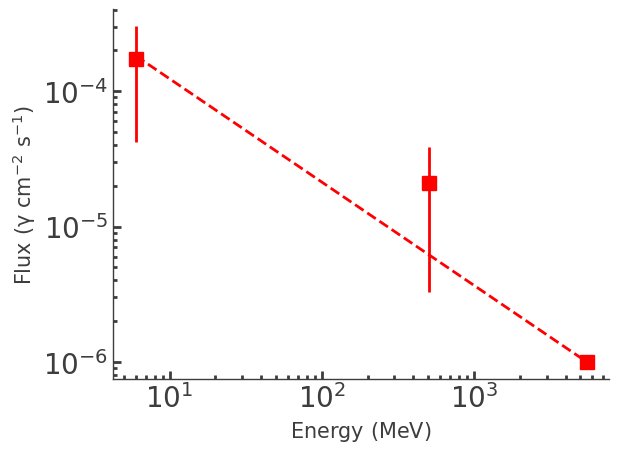

In [20]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# Convert lists to arrays
x_arr = np.array(x)
y_flux = np.array(y["F"])
y_flux_err = np.array(y["F_p"])

# mask=[1,2]
# x_arr = x_arr[mask]
# y_flux = y_flux[mask]
# y_flux_err = y_flux_err[mask]

def powerlaw(t, F0, alpha):
    return F0 * t ** (-alpha)

popt, pcov = curve_fit(powerlaw, x_arr, y_flux, p0=[1e-3, 1.0], sigma=y_flux_err, absolute_sigma=True, maxfev=10000)

print(popt)

plt.errorbar(x_arr,y_flux, y_flux_err, marker='s', ms=10, ls='', color='red')
plt.plot(x_arr, powerlaw(x_arr, *popt), ls='--', lw=2, color='red')
plt.yscale("log")
plt.xscale("log")
plt.tick_params(direction='in', axis='both', which='major', length=6, width=2, labelsize=20)
plt.tick_params(direction='in', axis='both', which='minor', length=3, width=2, labelsize=20)
plt.ylabel(r"$\rm Flux~(\gamma~cm^{-2}~s^{-1})$")
plt.xlabel(r"$\rm Energy~ (MeV)$")

In [21]:
TS = {}
for a in results.values():
    TS[list(a.data_list.keys())[0]] = a.compute_TS(
        "GRB", a.results.get_statistic_frame()
    )["TS"][0]

import pandas as pd

table_data = {
    "Parameter": [r"Flux (cm$^{-2}$ s$^{-1}$)", "Photon Index", "-log(L)", "BIC", "TS"]
}

for i, (LAT_name, jl) in enumerate(results.items()):
    res = jl.results
    
    # Create clean column name like "T1: 0.000-12.000 s"
    time_range = LAT_name.replace("LAT_", "")
    col_name = f"T{i+1}: {time_range} s"
    
    df_res = res.get_data_frame()
    
    # 1. Flux
    f_val = df_res.loc['GRB.spectrum.main.Powerlaw_flux.F', 'value']
    try:
        f_err_neg = df_res.loc['GRB.spectrum.main.Powerlaw_flux.F', 'negative_error']
        f_err_pos = df_res.loc['GRB.spectrum.main.Powerlaw_flux.F', 'positive_error']
        if np.isnan(f_err_neg) or np.isnan(f_err_pos):
            raise KeyError
        flux_str = f"({f_val:.1e} +{f_err_pos:.1e} -{abs(f_err_neg):.1e})"
    except (KeyError, ValueError):
        f_err = df_res.loc['GRB.spectrum.main.Powerlaw_flux.F', 'error']
        flux_str = f"({f_val:.1e} +/- {f_err:.1e})"
        
    # 2. Photon Index
    i_val = df_res.loc['GRB.spectrum.main.Powerlaw_flux.index', 'value']
    try:
        i_err_neg = df_res.loc['GRB.spectrum.main.Powerlaw_flux.index', 'negative_error']
        i_err_pos = df_res.loc['GRB.spectrum.main.Powerlaw_flux.index', 'positive_error']
        if np.isnan(i_err_neg) or np.isnan(i_err_pos):
            raise KeyError
        idx_str = f"{i_val:.2f} +{i_err_pos:.2f} -{abs(i_err_neg):.2f}"
    except (KeyError, ValueError):
        i_err = df_res.loc['GRB.spectrum.main.Powerlaw_flux.index', 'error']
        idx_str = f"{i_val:.2f} +/- {i_err:.2f}"
        
    # 3. -log(L)
    stat_frame = res.get_statistic_frame()
    logL = stat_frame.loc['total', '-log(likelihood)']
    logL_str = f"{logL:.1f}"
    
    # 4. BIC
    try:
        ic = res.get_statistic_measure_frame()
        if 'statistical measures' in ic.columns:
            bic = ic.loc['BIC', 'statistical measures']
        else:
            # Fallback if column name differs
            bic = ic.loc['BIC'].iloc[0]
        bic_str = f"{bic:.1f}"
    except Exception as e:
        bic_str = f"N/A ({e})"
        
    # 5. TS
    ts_val = jl.compute_TS("GRB", res.get_statistic_frame())["TS"][0]
    ts_str = f"{ts_val:.1f}"
    
    table_data[col_name] = [flux_str, idx_str, logL_str, bic_str, ts_str]

df_params = pd.DataFrame(table_data)

try:
    display(df_params)
except NameError:
    print(df_params.to_string(index=False))


Found Isotropic template for irf P8R3_SOURCE_V3: /home/void/miniforge3/envs/fermi/share/fermitools/refdata/fermi/galdiffuse/iso_P8R3_SOURCE_V3_v1.txt

Found Galactic template for IRF. P8R3_SOURCE_V3: /home/void/miniforge3/envs/fermi/share/fermitools/refdata/fermi/galdiffuse/gll_iem_v07.fits

Cutting the template around the ROI: 



13:01:39 INFO      set the minimizer to minuit                                             ]8;id=612403;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=33408;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/classicMLE/joint_likelihood.py#1046\1046]8;;\

         INFO      set the minimizer to minuit                                             ]8;id=956928;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=760010;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/classicMLE/joint_likelihood.py#1046\1046]8;;\


Found Isotropic template for irf P8R3_SOURCE_V3: /home/void/miniforge3/envs/fermi/share/fermitools/refdata/fermi/galdiffuse/iso_P8R3_SOURCE_V3_v1.txt

Found Galactic template for IRF. P8R3_SOURCE_V3: /home/void/miniforge3/envs/fermi/share/fermitools/refdata/fermi/galdiffuse/gll_iem_v07.fits

Cutting the template around the ROI: 




WARNING FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



...

13:01:59 INFO      set the minimizer to minuit                                             ]8;id=708588;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=838777;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/classicMLE/joint_likelihood.py#1046\1046]8;;\

         INFO      set the minimizer to minuit                                             ]8;id=653779;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=202446;file:///home/void/miniforge3/envs/fermi/lib/python3.9/site-packages/threeML/classicMLE/joint_likelihood.py#1046\1046]8;;\


Found Isotropic template for irf P8R3_SOURCE_V3: /home/void/miniforge3/envs/fermi/share/fermitools/refdata/fermi/galdiffuse/iso_P8R3_SOURCE_V3_v1.txt

Found Galactic template for IRF. P8R3_SOURCE_V3: /home/void/miniforge3/envs/fermi/share/fermitools/refdata/fermi/galdiffuse/gll_iem_v07.fits

Cutting the template around the ROI: 




WARNING FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



,Parameter,T1: 00.000-12.000 s,T2: 12.000-1000.000 s,T3: 1000.000-10000.000 s
0,Flux (cm$^{-2}$ s$^{-1}$),(1.8e-04 +1.3e-04 -7.9e-05),(2.3e-05 +1.6e-05 -1.2e-05),(1.0e-06 +1.1e-09 -1.5e-10)
1,Photon Index,-3.00 +0.00 -0.00,-2.35 +0.70 -0.35,-3.00 +0.03 -0.00
2,-log(L),15.3,55.1,343.5
3,BIC,33.9,115.6,697.0
4,TS,23.1,18.8,-4.4


### Scatter Plot and Source Probabilities
We generate accurate XML models from the likelihood fit per-interval, compute probabilities using gtsrcprob, and plot the events.

Running gtdiffrsp & gtsrcprob for interval 0-12...
adding source galdiff
adding source isodiff


Working on...
gll_ft1_tr_bn200412381_v00_filt.fit.....................................!


Running gtdiffrsp & gtsrcprob for interval 12-1000...
adding source galdiff
adding source isodiff


Working on...
Diffuse columns have already been computed for gll_ft1_tr_bn200412381_v00_filt.fit...skipping it.


Running gtdiffrsp & gtsrcprob for interval 1000-10000...
adding source galdiff
adding source isodiff


Working on...
Diffuse columns have already been computed for gll_ft1_tr_bn200412381_v00_filt.fit...skipping it.


Saved photon_probabilities.csv
Highest Energy GRB Photon: 1119.12 MeV at 133.24 s with prob 93.16%


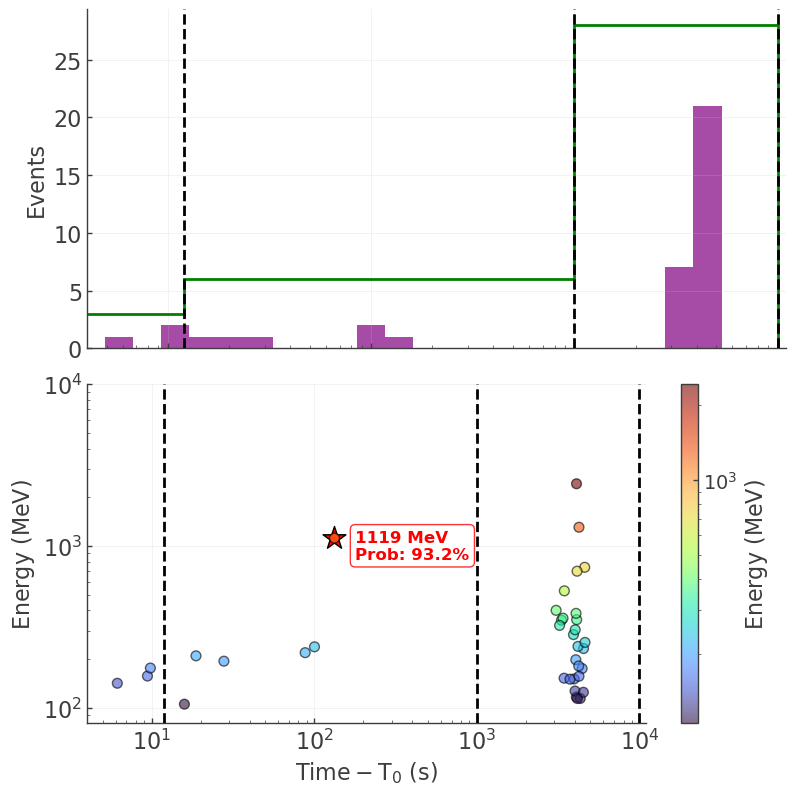

In [22]:
import os
import subprocess
import astropy.io.fits as pyfits

evfile = myLATdataset.filt_file
scfile = myLATdataset.ft2

prob_grb_global = np.zeros(len(lat_events))

for T0, T1 in zip(intervals[:-1], intervals[1:]):
    LAT_name = "LAT_%06.3f-%06.3f" % (T0, T1)
    if LAT_name in results:
        jl = results[LAT_name]
        df_res = jl.results.get_data_frame()
        try:
            F_val = df_res.loc['GRB.spectrum.main.Powerlaw_flux.F', 'value']
            index_val = df_res.loc['GRB.spectrum.main.Powerlaw_flux.index', 'value']
            a = 100.0
            b = 10000.0
            Scale = 100.0
            if index_val != -1.0:
                K = F_val * (index_val + 1) * (Scale**index_val) / (b**(index_val + 1) - a**(index_val + 1))
            else:
                K = F_val / (Scale * np.log(b/a))
            prefactor_val = K / 1e-9
        except KeyError:
            prefactor_val = 1.0
            index_val = -2.0
            
        xml_content = f"""<?xml version="1.0" ?>
<source_library title="source library" xmlns="http://fermi.gsfc.nasa.gov/source_library">
  <source name="GRB" type="PointSource">
    <spectrum type="PowerLaw">
      <parameter free="1" max="1000000.0" min="0.00001" name="Prefactor" scale="1e-09" value="{prefactor_val}"/>
      <parameter free="1" max="-1.0" min="-5.0" name="Index" scale="1.0" value="{index_val}"/>
      <parameter free="0" max="2000.0" min="30.0" name="Scale" scale="1.0" value="100.0"/>
    </spectrum>
    <spatialModel type="SkyDirFunction">
      <parameter free="0" max="360" min="-360" name="RA" scale="1.0" value="{myGRB['RA']}"/>
      <parameter free="0" max="90" min="-90" name="DEC" scale="1.0" value="{myGRB['DEC']}"/>
    </spatialModel>
  </source>
  <source name="isodiff" type="DiffuseSource">
    <spectrum type="FileFunction" file="/home/void/miniforge3/envs/fermi/share/fermitools/refdata/fermi/galdiffuse/iso_P8R3_TRANSIENT020E_V3_v1.txt">
      <parameter free="1" max="10" min="1e-05" name="Normalization" scale="1" value="1"/>
    </spectrum>
    <spatialModel type="ConstantValue">
      <parameter free="0" max="10" min="0" name="Value" scale="1" value="1"/>
    </spatialModel>
  </source>
  <source name="galdiff" type="DiffuseSource">
    <spectrum type="PowerLaw">
      <parameter free="1" max="10" min="0" name="Prefactor" scale="1" value="1"/>
      <parameter free="0" max="1" min="-1" name="Index" scale="1" value="0"/>
      <parameter free="0" max="200" min="50" name="Scale" scale="1" value="100"/>
    </spectrum>
    <spatialModel type="SpatialMap" file="/home/void/miniforge3/envs/fermi/share/fermitools/refdata/fermi/galdiffuse/gll_iem_v07.fits">
      <parameter free="0" max="1000" min="0.001" name="Prefactor" scale="1" value="1"/>
    </spatialModel>
  </source>
</source_library>
"""
        with open("source_model_gtsrcprob.xml", "w") as f:
            f.write(xml_content)
            
        print(f"Running gtdiffrsp & gtsrcprob for interval {T0}-{T1}...")
        subprocess.run(f"gtdiffrsp evfile={evfile} scfile={scfile} srcmdl=source_model_gtsrcprob.xml irfs=P8R3_TRANSIENT020E_V3", shell=True)
        subprocess.run(f"gtsrcprob evfile={evfile} scfile={scfile} outfile=events_with_probs.fits srcmdl=source_model_gtsrcprob.xml irfs=P8R3_TRANSIENT020E_V3", shell=True)
        
        with pyfits.open('events_with_probs.fits') as prob_file:
            prob_data = prob_file["EVENTS"].data
            
        mask = (event_times >= T0) & (event_times < T1)
        prob_grb_global[mask] = prob_data['GRB'][mask]

prob_grb = prob_grb_global

df_probs = pd.DataFrame({
    "Time [s]": event_times,
    "Energy [MeV]": lat_events["ENERGY"],
    "Prob_GRB": prob_grb
})
df_probs.to_csv("photon_probabilities.csv", index=False)
print("Saved photon_probabilities.csv")

high_prob_mask = prob_grb > 0.05
if np.any(high_prob_mask):
    high_prob_energies = lat_events["ENERGY"][high_prob_mask]
    high_prob_times = event_times[high_prob_mask]
    high_prob_probs = prob_grb[high_prob_mask]
    
    best_idx = np.argmax(high_prob_energies)
    max_energy_grb = high_prob_energies[best_idx]
    max_time_grb = high_prob_times[best_idx]
    max_prob_grb = high_prob_probs[best_idx]
else:
    max_idx = np.argmax(lat_events["ENERGY"])
    max_energy_grb = lat_events["ENERGY"][max_idx]
    max_time_grb = event_times[max_idx]
    max_prob_grb = prob_grb[max_idx]

print(f"Highest Energy GRB Photon: {max_energy_grb:.2f} MeV at {max_time_grb:.2f} s with prob {max_prob_grb:.2%}")

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 8))
plt.sca(axs[0])
plt.hist(event_times, bins=log_bins, color='purple', alpha=0.7)
plt.hist(event_times, intervals, histtype="step", color='green', lw=2)
plt.ylabel("Events", fontsize=16)
axs[0].tick_params(direction='in', axis='both', which='major', labelsize=16)
axs[0].tick_params(direction='in', axis='both', which='minor', labelsize=16)

plt.sca(axs[1])
sc = plt.scatter(
    event_times,
    lat_events["ENERGY"],
    marker="o",
    c=lat_events["ENERGY"],
    cmap="turbo",
    edgecolors="black",
    norm="log",
    alpha=0.6,
    zorder=20,
    s=50
)

plt.scatter(
    max_time_grb,
    max_energy_grb,
    marker="*",
    color="red",
    edgecolors="black",
    s=300,
    zorder=15
)

plt.annotate(
    f"{max_energy_grb:.0f} MeV\nProb: {max_prob_grb:.1%}",
    (max_time_grb, max_energy_grb),
    textcoords="offset points",
    xytext=(15, -15),
    ha='left',
    fontsize=12,
    color='red',
    fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="red", alpha=0.8)
)

plt.xscale("log")  
plt.yscale("log")
plt.xlim(4, 11000)
plt.ylim(80, 1e4)
plt.ylabel(r"$\rm Energy~(MeV)$", fontsize=16)
plt.xlabel(r"$\rm Time - T_{0}~(s)$", fontsize=16)

cbar = plt.colorbar(sc, ax=axs[1])
cbar.ax.tick_params(labelsize=14, direction='in')
cbar.set_label(r"$\rm Energy~(MeV)$", fontsize=16)

axs[1].tick_params(direction='in', axis='both', which='major', labelsize=16)
axs[1].tick_params(direction='in', axis='both', which='minor', labelsize=16)

for interval in intervals:
    if interval > 0:
        plt.axvline(interval, color='k', linestyle='--', zorder=10)
        axs[0].axvline(interval, color='k', linestyle='--', zorder=10)

axs[0].grid(True, alpha=0.3)
axs[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('lat_ph.pdf', bbox_inches='tight')